<a href="https://colab.research.google.com/github/idrees006/DecodeLabs-Internship/blob/main/Full_Project_DigiSkill.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Of Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Load DataSet

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/ML_datasets/bmw_cars_market_dataset_synthetic.csv')

print("First 5 rows of the dataset:")
print(df.head())
print("------------------------------")
print("------------------------------")

print("DataSet Info")
print(df.info())
print("------------------------------")
print("------------------------------")

print("DataSet Description")
print(df.describe())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
First 5 rows of the dataset:
   car_id     model  year  ...  accident_history  service_history country_sold
0       1        X5  2016  ...                no          partial  Netherlands
1       2  1 Series  2022  ...                no          partial       France
2       3        X1  2012  ...                no             full  Netherlands
3       4        X5  2022  ...                no              NaN       France
4       5  7 Series  2023  ...                no             full        Spain

[5 rows x 20 columns]
------------------------------
------------------------------
DataSet Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   car_id                        10000 non

Checking Missing Values
car_id                            0
model                             0
year                              0
engine_size                     243
horsepower                        0
fuel_type                         0
transmission                    215
drivetrain                        0
mileage_km                        0
fuel_consumption_l_per_100km    246
price_usd                         0
co2_emissions_g_km              225
doors                             0
seats                             0
body_type                         0
color                           239
owner_count                     255
accident_history                254
service_history                 231
country_sold                      0
dtype: int64


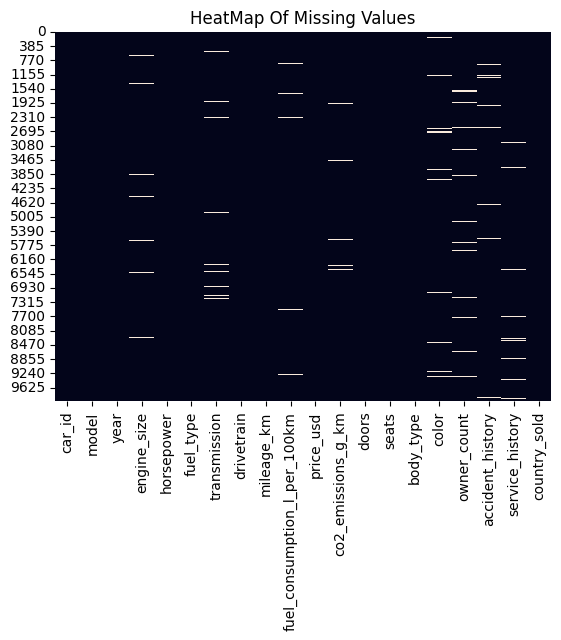

In [ ]:
#Checking Messing Values
print("Checking Missing Values")
print(df.isnull().sum())

#Visualizing Missing Values
sns.heatmap(df.isnull(),cbar=False)
plt.title("HeatMap Of Missing Values")
plt.show()

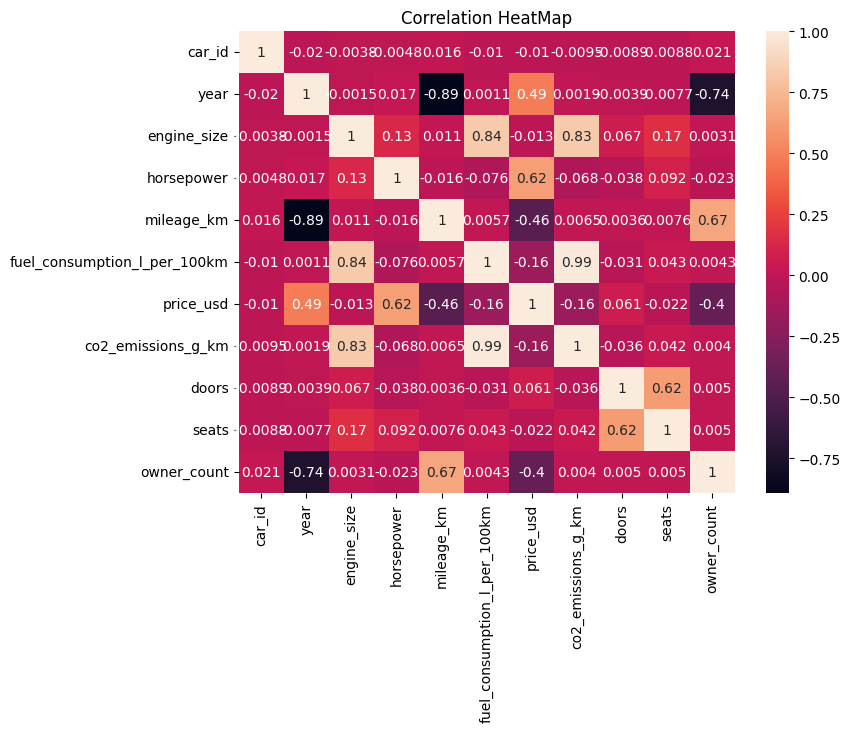

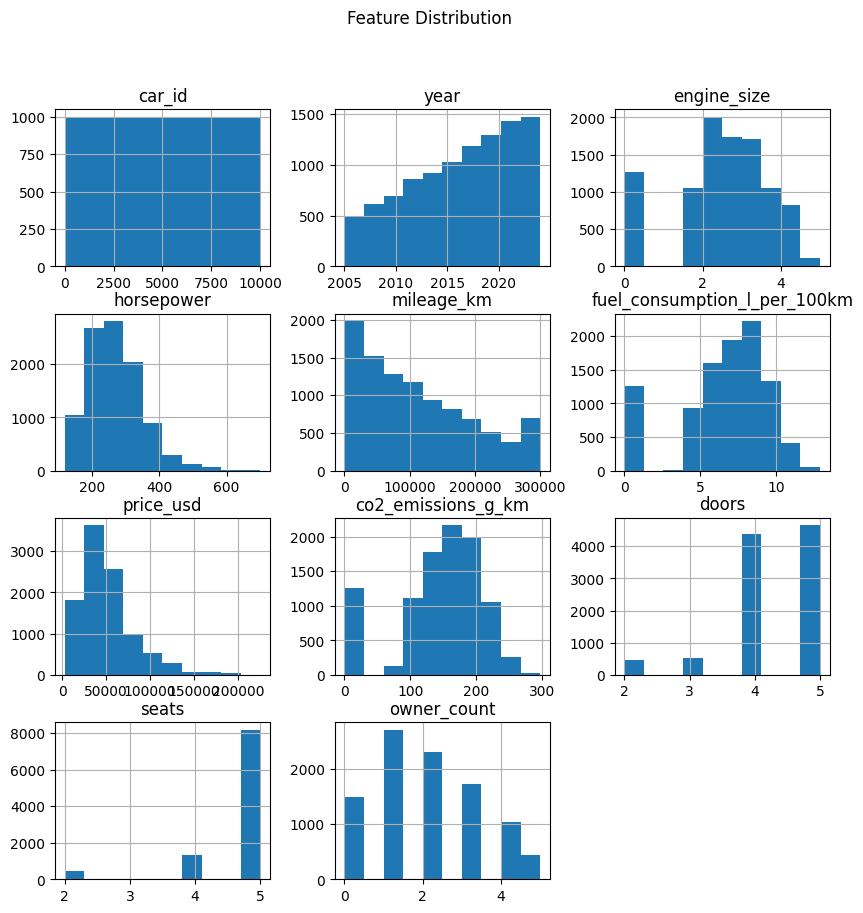

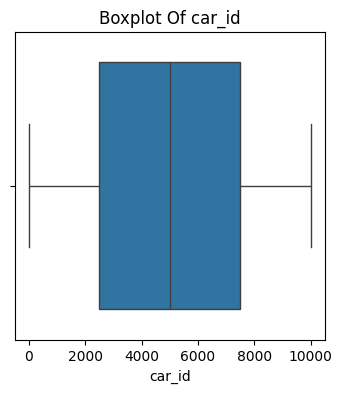

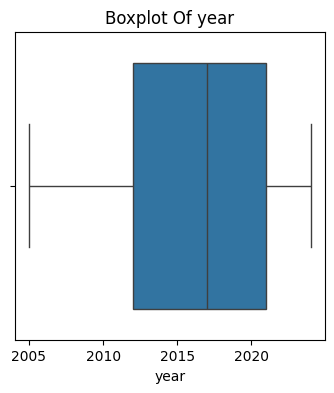

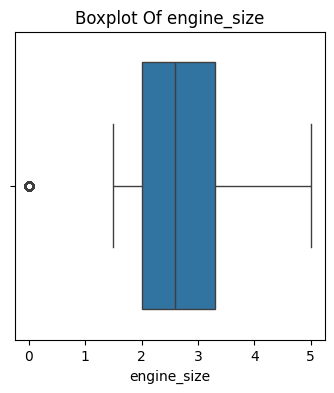

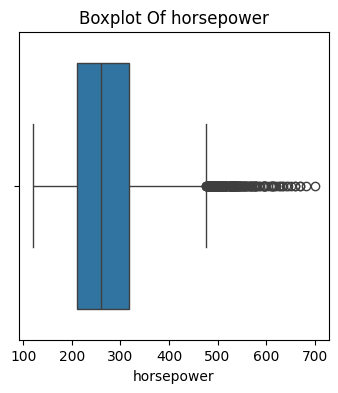

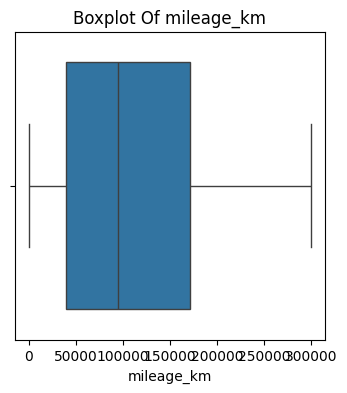

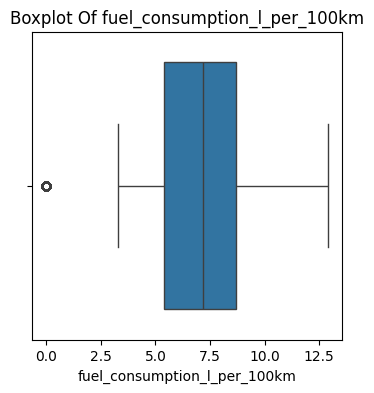

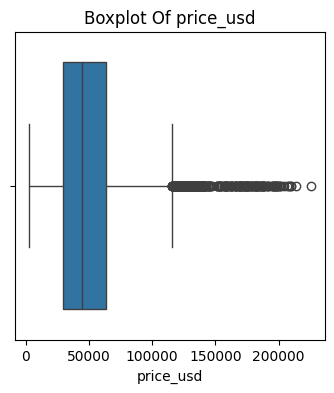

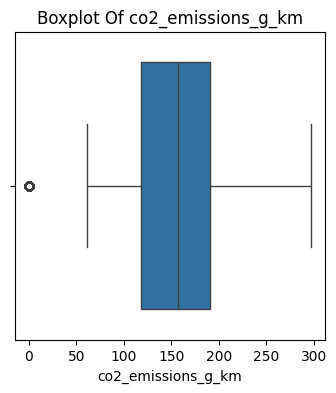

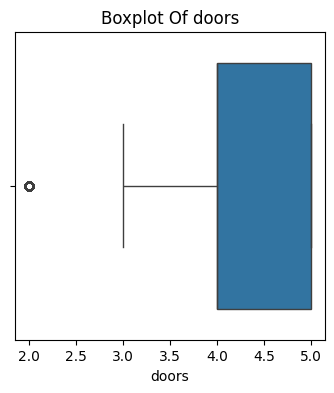

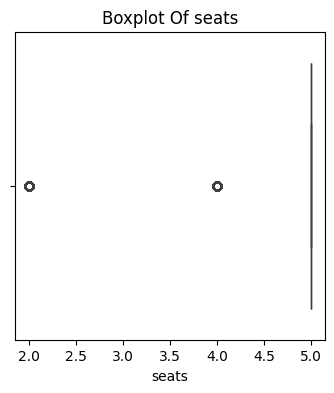

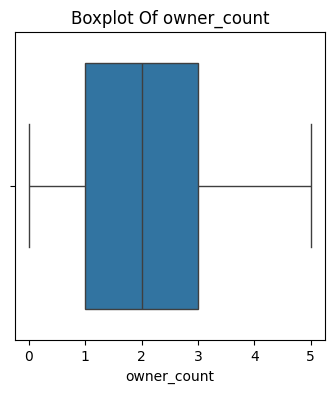

In [ ]:
#Coorelation HeatMap
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.title("Correlation HeatMap")
plt.show()

#Distribution Of Numaric Feature
df.hist(figsize=(10,10))
plt.suptitle("Feature Distribution")
plt.show()

#Boxplot Of Outlier
num_cols = df.select_dtypes(include=np.number).columns
for col in num_cols:
  plt.figure(figsize=(4,4))
  sns.boxplot(x=df[col])
  plt.title(f"Boxplot Of {col}")
  plt.show()

# Data Cleaning

In [ ]:
#Drop Duplicate Values
df.drop_duplicates(inplace=True)

# Identify Categorical Columns
cat_cols = df.select_dtypes(include=['object']).columns

#Label Encoder Categorical Columns
le = LabelEncoder()
for col in cat_cols:
  df[col] = le.fit_transform(df[col].astype(str))

# Identify Numerical Columns
num_cols = df.select_dtypes(include=np.number).columns
imputer = SimpleImputer(strategy='mean')
df[num_cols] = imputer.fit_transform(df[num_cols])

print("DataSet Info")
print(df.info())
print("------------------------------")
print("------------------------------")

print("DataSet Description")
print(df.describe())

DataSet Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   car_id                        10000 non-null  float64
 1   model                         10000 non-null  float64
 2   year                          10000 non-null  float64
 3   engine_size                   10000 non-null  float64
 4   horsepower                    10000 non-null  float64
 5   fuel_type                     10000 non-null  float64
 6   transmission                  10000 non-null  float64
 7   drivetrain                    10000 non-null  float64
 8   mileage_km                    10000 non-null  float64
 9   fuel_consumption_l_per_100km  10000 non-null  float64
 10  price_usd                     10000 non-null  float64
 11  co2_emissions_g_km            10000 non-null  float64
 12  doors                         10000 non-null  fl

# Model Training And Evaluation

In [ ]:
# Define x , y features
x = df.iloc[ :, :-1]
y = df.iloc[:, -1]


# Spliting into Train Test
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)


# Feature Scaling
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
# Define ML Models

models = {
    "Logistic Regression" : LogisticRegression(max_iter=200),
    "Random Forest"       : RandomForestClassifier(),
    "KNN"                 : KNeighborsClassifier(),
    "Decision Tree"       : DecisionTreeClassifier(),
    "SVM"                 : SVC()
}

In [ ]:
result = {}
for name, model in models.items():
  print("/n=================")
  print(f"Model Name : {name}")
  print("=================")

  model.fit(x_train, y_train)
  y_pred = model.predict(x_test)

  acc = accuracy_score(y_test, y_pred)
  cl_report = classification_report(y_test, y_pred)
  c_matrics = confusion_matrix(y_test, y_pred)
  result[name] = acc

  print(f"Accuracy : {acc}")
  print("Classification Report")
  print(cl_report)
  print("Confusion Matrix")
  print(c_matrics)


/n=================
Model Name : Logistic Regression
Accuracy : 0.1335
Classification Report
              precision    recall  f1-score   support

         0.0       0.12      0.09      0.11       262
         1.0       0.12      0.12      0.12       225
         2.0       0.15      0.16      0.16       240
         3.0       0.13      0.14      0.13       249
         4.0       0.13      0.23      0.16       260
         5.0       0.18      0.19      0.18       266
         6.0       0.12      0.11      0.12       257
         7.0       0.06      0.01      0.02       241

    accuracy                           0.13      2000
   macro avg       0.13      0.13      0.12      2000
weighted avg       0.13      0.13      0.13      2000

Confusion Matrix
[[24 30 29 34 70 42 24  9]
 [29 26 36 30 35 25 38  6]
 [20 20 39 42 58 22 33  6]
 [25 30 34 35 64 32 27  2]
 [28 28 28 29 60 46 30 11]
 [27 24 38 30 68 51 24  4]
 [21 37 25 40 63 34 29  8]
 [21 22 31 35 57 38 34  3]]
/n=================
Mo

In [ ]:
# Model Comperision
result_df = pd.DataFrame(result.items(), columns=["model", "Accuracy"])
result_df = result_df.sort_values(by="Accuracy", ascending=False)
print(result_df)

                 model  Accuracy
0  Logistic Regression    0.1335
1        Random Forest    0.1325
3        Decision Tree    0.1255
4                  SVM    0.1235
2                  KNN    0.1190


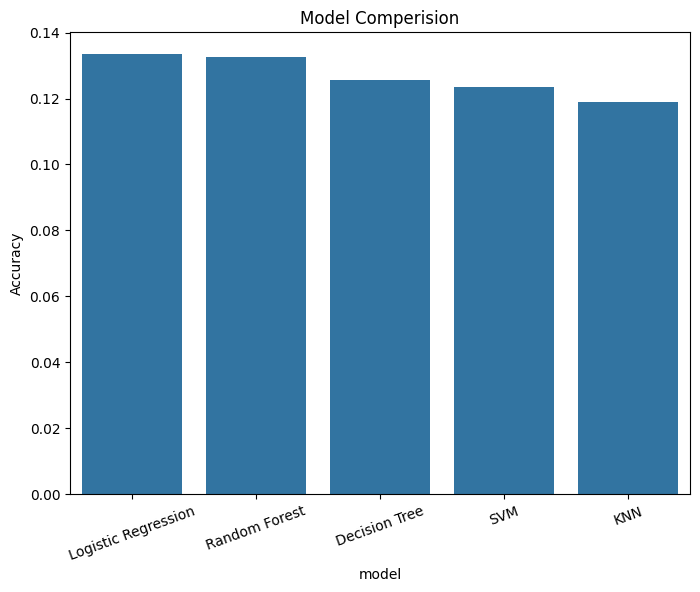

In [ ]:
plt.figure( figsize=(8, 6))
sns.barplot(x="model", y="Accuracy", data=result_df)
plt.title("Model Comperision")
plt.xticks(rotation=20)
plt.show()